# Task 1: Health Insurance Cost Prediction

## Business Brief
An insurance company wants to predict the yearly medical charges of each customer, so it can price its policies correctly.

## Objective
Build four regression models, compare them, and choose the one that predicts `charges` most accurately.

## Dataset
[https://www.kaggle.com/datasets/mirichoi0218/insurance](https://www.kaggle.com/datasets/mirichoi0218/insurance) (file: `insurance.csv`)

| Column | Description |
|---|---|
| `age` | Customer age |
| `sex` | male / female |
| `bmi` | Body mass index |
| `children` | Number of dependents |
| `smoker` | yes / no |
| `region` | Residential region |
| `charges` | Yearly medical charges in USD (**target**) |

**Rule:** the test set must not be used for training.

## Step 1
Load the dataset and display the first 5 rows.

In [250]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [251]:
df = pd.read_csv('/content/insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## Step 2
Show the number of rows and columns, the missing values, and the duplicated rows.

In [252]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [253]:
print(f'Number of rows: {df.shape[0]}')
print(f'Number of columns: {df.shape[1]}')
print(f'Number of missing values: {df.isna().sum().sum()}')
print(f'Number of duplicated rows: {df.duplicated().sum()}')

Number of rows: 1338
Number of columns: 7
Number of missing values: 0
Number of duplicated rows: 1


In [254]:
df.drop_duplicates(inplace=True)

In [255]:
df.duplicated().sum()

np.int64(0)

## Step 3
Convert `sex` and `smoker` into numbers.

In [256]:
df['region'].unique()

array(['southwest', 'southeast', 'northwest', 'northeast'], dtype=object)

In [257]:
df['sex'] = df['sex'].map({'female': 0, 'male': 1})
df['smoker'] = df['smoker'].map({'no': 0, 'yes': 1})
df['region'] = df['region'].map({'southwest': 1.0, 'southeast': 1.1, 'northwest': 2.0, 'northeast': 2.1})
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,1.0,16884.92400
1,18,1,33.770,1,0,1.1,1725.55230
2,28,1,33.000,3,0,1.1,4449.46200
3,33,1,22.705,0,0,2.0,21984.47061
4,32,1,28.880,0,0,2.0,3866.85520


## Step 4
Print the correlation of each numeric column with `charges`, and plot `age` vs `charges` colored by `smoker`.

Correlation with charges:
charges     1.000000
smoker      0.787234
age         0.298308
bmi         0.198401
children    0.067389
sex         0.058044
region     -0.020971
Name: charges, dtype: float64


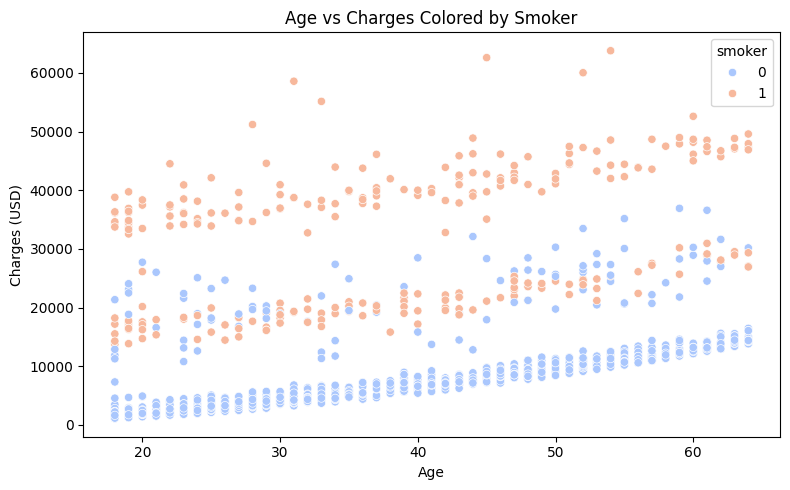

In [258]:
corr = df.corr(numeric_only=True)['charges'].sort_values(ascending=False)
print("Correlation with charges:")
print(corr)

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='age', y='charges', hue='smoker', palette='coolwarm')
plt.title('Age vs Charges Colored by Smoker')
plt.xlabel('Age')
plt.ylabel('Charges (USD)')
plt.tight_layout()

## Step 5
Define `X` and `y`, then split the data into 80% train and 20% test with `random_state=42`.

In [259]:
x = df[['age', 'sex', 'bmi', 'smoker', 'region']]
y = df['charges']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

## Step 6
Train these four models, each in its own cell:
   1. Simple Linear Regression
   2. Multiple Linear Regression
   3. Polynomial Regression (Pipeline)
   4. KNN Regression (Pipeline with scaling)

In [260]:
slr = LinearRegression()
slr.fit(x_train[['smoker']], y_train)

LinearRegression()

In [261]:
mlr = LinearRegression()
mlr.fit(x_train, y_train)

LinearRegression()

In [262]:
poly_reg = Pipeline([
    ('poly', PolynomialFeatures(degree=2)),
    ('lr', LinearRegression())
])
poly_reg.fit(x_train, y_train)

Pipeline(steps=[('poly', PolynomialFeatures()), ('lr', LinearRegression())])

In [263]:
knn_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor(n_neighbors=5))
])
knn_reg.fit(x_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('knn', KNeighborsRegressor())])

## Step 7
Predict on the test set with each model and display a table of actual vs predicted values (first 8 rows).

In [264]:
y_pred_simple = slr.predict(x_test[['smoker']])
y_pred_multiple = mlr.predict(x_test)
y_pred_poly = poly_reg.predict(x_test)
y_pred_knn = knn_reg.predict(x_test)

predictions_df = pd.DataFrame({
    'Actual': y_test.values,
    'Simple_LR': y_pred_simple,
    'Multiple_LR': y_pred_multiple,
    'Polynomial_LR': y_pred_poly,
    'KNN_Regression': y_pred_knn
})

predictions_df.head(8)

,Actual,Simple_LR,Multiple_LR,Polynomial_LR,KNN_Regression
0,8688.85885,8498.478840,8611.292820,9618.601853,8476.322320
1,5708.86700,8498.478840,4022.798413,5409.442134,4182.905700
2,11436.73815,8498.478840,13541.693513,12271.091122,15289.256598
3,38746.35510,31135.925203,30891.548210,35318.264243,38059.787550
4,4463.20510,8498.478840,8520.449248,4900.917940,6734.640644
5,9304.70190,8498.478840,12763.032920,10258.983617,8474.827060
6,38511.62830,31135.925203,29765.737111,38273.082256,40717.821172
7,2150.46900,8498.478840,1854.029830,3964.016311,6839.631968


## Step 8
Calculate MAE, MSE, RMSE, and R² for each model and display them in one comparison table.

In [265]:
results = []
for name, preds in [
    ('Simple LR', y_pred_simple),
    ('Multiple LR', y_pred_multiple),
    ('Polynomial R', y_pred_poly),
    ('KNN R', y_pred_knn)
]:
    mae = mean_absolute_error(y_test, preds)
    mse = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, preds)
    results.append({'Model': name, 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2})

comparison_df = pd.DataFrame(results)
print("Comparison Table:")
print(comparison_df.round(4))

Comparison Table:
          Model        MAE           MSE       RMSE      R2
0     Simple LR  5830.6357  6.003930e+07  7748.5033  0.6733
1   Multiple LR  4173.2915  3.540451e+07  5950.1693  0.8073
2  Polynomial R  2802.9392  2.091209e+07  4572.9739  0.8862
3         KNN R  3042.1332  2.454898e+07  4954.6931  0.8664


## Step 9
Plot a bar chart comparing the R² of the four models.

/tmp/ipykernel_1965/3371801844.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparison_df, x='Model', y='R2', palette='viridis')


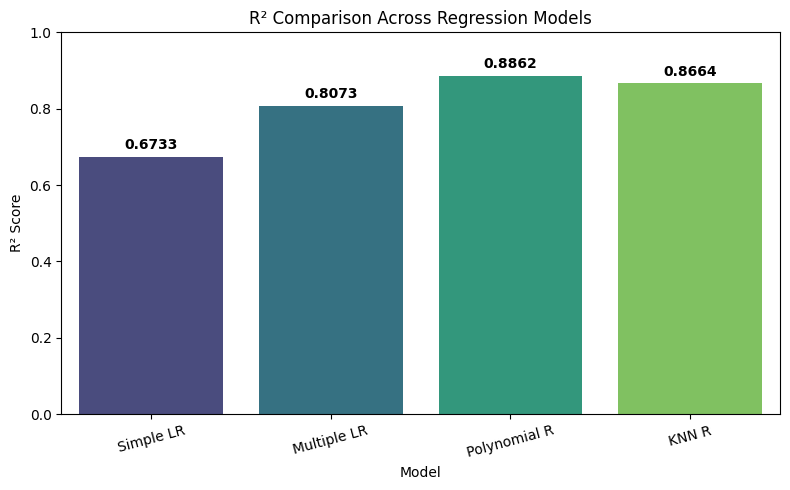

In [266]:
plt.figure(figsize=(8, 5))
sns.barplot(data=comparison_df, x='Model', y='R2', palette='viridis')
plt.title('R² Comparison Across Regression Models')
plt.ylabel('R² Score')
plt.xlabel('Model')
plt.ylim(0, 1)
plt.xticks(rotation=15)
for index, row in comparison_df.iterrows():
    plt.text(index, row.R2 + 0.02, f"{row.R2:.4f}", ha='center', fontweight='bold')
plt.tight_layout()

## Step 10
Create a new customer and predict their charges using your best model.

In [267]:
new_customer = pd.DataFrame({
    'age': [35],
    'sex': [1],
    'bmi': [28.5],
    'smoker': [0],
    'region': [1.0]
})

predicted_charge = poly_reg.predict(new_customer)[0]
print(f"Predicted Insurance Charges: ${predicted_charge:.2f}")

Predicted Insurance Charges: $6438.46


## Step 11
Write a 3-sentence conclusion: which model is best, its R², and why.

*Polynomial Regression is the best model among the four tested regression models. It achieved the highest R² score of 0.8862 and the lowest RMSE of 4572.97 on the test set. It outperforms the other models because polynomial features capture the non-linear relationships and interaction effects between variables such as smoking, BMI, and age.*

## Bonus
Deploy your best model as a web app using **Gradio**, so anyone can enter a customer's details and get the predicted charges.

In [268]:
import gradio as gr

def predict_charges(age, sex, bmi, smoker, region):
    sex_num = 1 if sex == "male" else 0
    smoker_num = 1 if smoker == "yes" else 0
    region_map = {'southwest': 1.0, 'southeast': 1.1, 'northwest': 2.0, 'northeast': 2.1}

    customer_df = pd.DataFrame({
        'age': [age],
        'sex': [sex_num],
        'bmi': [bmi],
        'children': [children],
        'smoker': [smoker_num],
        'region': [region_map[region]]
    })
    prediction = poly_reg.predict(customer_df)[0]
    return f"${prediction:,.2f}"

app = gr.Interface(
    fn=predict_charges,
    inputs=[
        gr.Number(label="Age", value=35),
        gr.Radio(["female", "male"], label="Sex", value="male"),
        gr.Number(label="BMI", value=28.5),
        gr.Slider(0, 5, step=1, label="Children", value=2),
        gr.Radio(["no", "yes"], label="Smoker", value="no"),
        gr.Dropdown(["southwest", "southeast", "northwest", "northeast"], label="Region", value="southwest")
    ],
    outputs=gr.Textbox(label="Predicted Yearly Charges"),
    title="Health Insurance Cost Predictor"
)

app.launch()

/usr/local/lib/python3.13/dist-packages/gradio/utils.py:1379: UserWarning: Expected 5 arguments for function <function predict_charges at 0x7bfc50bb8900>, received 6.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/gradio/utils.py:1387: UserWarning: Expected maximum 5 arguments for function <function predict_charges at 0x7bfc50bb8900>, received 6.
  warnings.warn(


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://540d40180dcae3ecab.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
